Імпорт необхідних бібліотек

In [6]:
import networkx as nx
import matplotlib.pyplot as plt
import random
import math

Функція генерації топології

In [7]:
def generate_graph_topology(num_nodes=25, edges_to_remove=5, weight_min=1, weight_max=10):
    G = nx.Graph()
    
    # Визначаємо розміри сітки (рядки та стовпці)
    cols = math.ceil(math.sqrt(num_nodes))
    rows = math.ceil(num_nodes / cols)
    
    # Додавання вузлів (nodes) з адресами
    node_count = 0
    for r in range(rows):
        for c in range(cols):
            if node_count >= num_nodes:
                break
            
            node_id = (r, c)
            address = f"10.0.{r}.{c}"
            # Зберігаємо адресу та позицію (для малювання у вигляді сітки)
            G.add_node(node_id, address=address, pos=(c, -r)) 
            node_count += 1
            
    # Додавання ребер (edges) з випадковою вагою (weight)
    for r in range(rows):
        for c in range(cols):
            if not G.has_node((r, c)): 
                continue
                
            # Зв'язок зі східним (East) сусідом
            if G.has_node((r, c+1)):
                weight = random.randint(weight_min, weight_max)
                G.add_edge((r, c), (r, c+1), weight=weight)
                
            # Зв'язок з південним (South) сусідом
            if G.has_node((r+1, c)):
                weight = random.randint(weight_min, weight_max)
                G.add_edge((r, c), (r+1, c), weight=weight)
                
    # Видалення заданої кількості ребер зі збереженням зв'язності
    removed_count = 0
    attempts = 0
    max_attempts = 1000 # Запобіжник від нескінченного циклу
    
    while removed_count < edges_to_remove and attempts < max_attempts:
        edges = list(G.edges())
        if not edges: 
            break
            
        # Обираємо випадкове ребро
        u, v = random.choice(edges)
        weight = G[u][v]['weight']
        
        # Тимчасово видаляємо ребро
        G.remove_edge(u, v)
        
        # Перевіряємо, чи залишився граф зв'язним
        if nx.is_connected(G):
            removed_count += 1
        else:
            # Якщо граф розпався, повертаємо ребро назад
            G.add_edge(u, v, weight=weight)
            
        attempts += 1
        
    if removed_count < edges_to_remove:
        print(f"Увага: Вдалося видалити лише {removed_count} ребер без втрати зв'язності.")
        
    return G

Функція візуалізації графу

In [8]:
def visualize_graph(G):
    plt.figure(figsize=(12, 10))
    
    # Отримуємо атрибути для малювання
    pos = nx.get_node_attributes(G, 'pos')
    labels = nx.get_node_attributes(G, 'address')
    edge_labels = nx.get_edge_attributes(G, 'weight')
    
    # Малюємо вузли та ребра
    nx.draw(G, pos, labels=labels, with_labels=True, 
            node_color='lightgreen', node_size=3000, 
            font_size=9, font_weight='bold', 
            edge_color='gray', width=2)
    
    # Малюємо ваги ребер
    nx.draw_networkx_edge_labels(G, pos, edge_labels=edge_labels, font_color='red', font_size=10)
    
    plt.title("Граф-топологія мережі", fontsize=16)
    plt.axis('off')
    plt.show()

Виконання (Main)

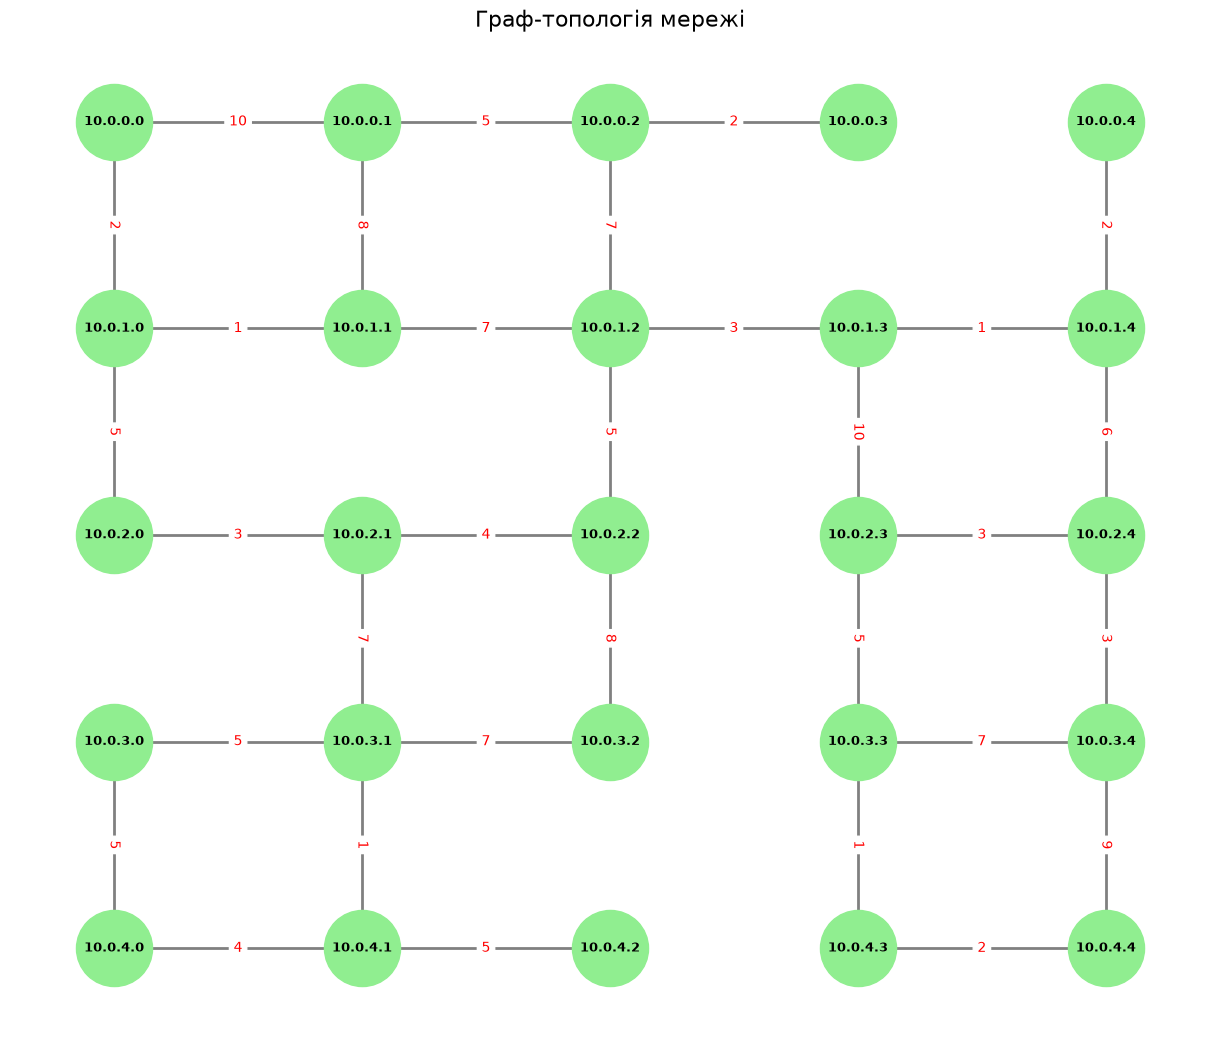

In [9]:
# Задання конфігурованих параметрів
NUM_NODES = 25
EDGES_TO_REMOVE = 8
WEIGHT_MIN = 1
WEIGHT_MAX = 10

# Генерація графу
network_graph = generate_graph_topology(
    num_nodes=NUM_NODES, 
    edges_to_remove=EDGES_TO_REMOVE, 
    weight_min=WEIGHT_MIN, 
    weight_max=WEIGHT_MAX
)

# Візуалізація результату
visualize_graph(network_graph)